# ============================================================
# CAPITOLO 1: SETUP AND CONFIGURATION
# Replication of Hubicka, Marcjasz, Weron (2019) - ARX Model
# ============================================================

In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy import stats

# --- General Configuration ---
CSV_PATH = "Dati_progetto_completo.csv"
PRICE_COL = "Zonal Price"
LOAD_COL = "Forecasted Total Load"
TEST_START = pd.Timestamp("2012-12-29")
TEST_END = pd.Timestamp("2013-12-17")

# --- Window Configurations ---
WINDOWS_ALL = list(range(28, 729, 28))        # 26 windows (step 28)
WINDOWS_SEL = [28, 56, 84, 714, 721, 728]     # AW selected by the paper
WINDOWS_STEP_7 = list(range(28, 729, 7))      # Step 7 (for specific table rows)
WINDOWS_STEP_14 = list(range(28, 729, 14))    # Step 14 (for specific table rows)

# Union of all windows needed for the final table
ALL_NEEDED_WINDOWS = sorted(set(WINDOWS_ALL) | set(WINDOWS_SEL) | set(WINDOWS_STEP_7) | set(WINDOWS_STEP_14))

OUTDIR = Path("output_arx_replica")
OUTDIR.mkdir(exist_ok=True)

# ============================================================
# CAPITOLO 2: DATA LOADING AND PREPROCESSING
# ============================================================

In [8]:


df = pd.read_csv(CSV_PATH)

# Parse datetime (original format: MMDDYYYY H:MM)
df["datetime"] = pd.to_datetime(df["timestamp"], format="%m%d%Y %H:%M")
df = df.sort_values("datetime").reset_index(drop=True)

df["date"]  = df["datetime"].dt.normalize()
df["hour"]  = df["datetime"].dt.hour
df = df.drop_duplicates(["date", "hour"])

# Create Day x Hour matrices (Pivot)
price = df.pivot(index="date", columns="hour", values=PRICE_COL).sort_index()
load  = df.pivot(index="date", columns="hour", values=LOAD_COL).sort_index()

price = price.reindex(columns=range(24))
load  = load.reindex(columns=range(24))

# Clean data: keep only days with complete price and load data
valid = (~price.isna().any(axis=1)) & (~load.isna().any(axis=1))
price = price.loc[valid]
load  = load.loc[valid]

dates = price.index
P = price.values.astype(float)
L = load.values.astype(float)

# Logarithmic transformation
logP = np.log(P)
logL = np.log(L)
n_days, n_hours = logP.shape

# Scopriamo il giorno mancante
expected_dates = pd.date_range(start=df["date"].min(), end=df["date"].max(), freq='D')
missing_dates = set(expected_dates) - set(dates)

print(f"Giorni attesi: {len(expected_dates)}")
print(f"Giorni validi: {len(dates)}")
print(f"Giorno/i eliminato/i: {missing_dates}")

print(f"Valid days: {n_days} | Period: {dates[0].date()} to {dates[-1].date()}")

Giorni attesi: 1082
Giorni validi: 1081
Giorno/i eliminato/i: {Timestamp('2013-03-10 00:00:00')}
Valid days: 1081 | Period: 2011-01-01 to 2013-12-17


# ============================================================
# CAPITOLO 3: ARX FEATURE ENGINEERING
# ============================================================

In [4]:


def build_arx_features(logP, logL, dates):
    """
    Constructs a 3D tensor F[days, hours, features] for the ARX model.
    """
    n_days, n_hours = logP.shape
    F = np.full((n_days, n_hours, 9), np.nan) 
    
    dow = dates.dayofweek
    is_mon = (dow == 0).astype(float)
    is_sat = (dow == 5).astype(float)
    is_sun = (dow == 6).astype(float)
    
    for d in range(7, n_days): # Start from day 7 to avoid missing lags
        pmin_prev = np.min(logP[d-1, :])
        for h in range(n_hours):
            F[d, h, 0] = 1.0                   # Intercept
            F[d, h, 1] = logP[d-1, h]          # Lag 1 day
            F[d, h, 2] = logP[d-2, h]          # Lag 2 days
            F[d, h, 3] = logP[d-7, h]          # Lag 7 days
            F[d, h, 4] = pmin_prev             # Minimum price of previous day
            F[d, h, 5] = logL[d, h]            # Exogenous variable (Load forecast)
            F[d, h, 6] = is_mon[d]             # Monday dummy
            F[d, h, 7] = is_sat[d]             # Saturday dummy
            F[d, h, 8] = is_sun[d]             # Sunday dummy
    return F

F = build_arx_features(logP, logL, dates)

# ============================================================
# CAPITOLO 4: ROLLING WINDOW BACKTESTING
# ============================================================

In [5]:


test_mask = (dates >= TEST_START) & (dates <= TEST_END)
test_idx = np.where(test_mask)[0]
test_idx = test_idx[test_idx >= 7] # Need at least 7 days of history
actual = P[test_idx, :]

def forecast_arx_window(F, logP, test_idx, T, n_hours=24):
    """Estimates rolling OLS for each day and hour."""
    n_test = len(test_idx)
    pred = np.full((n_test, n_hours), np.nan)
    
    for j, d in enumerate(test_idx):
        # max(0, d - T) prevents data leakage at the beginning of the series
        train_idx = np.arange(max(0, d - T), d) 
        
        for h in range(n_hours):
            X = F[train_idx, h, :]
            y = logP[train_idx, h]
            
            # Boolean mask to drop rows with missing values (NaN)
            ok = (~np.isnan(X).any(axis=1)) & (~np.isnan(y))
            
            # OLS Estimation
            beta, *_ = np.linalg.lstsq(X[ok], y[ok], rcond=None)
            
            # Forecast and convert back from log scale using exp()
            pred[j, h] = np.exp(F[d, h, :] @ beta)
            
    return pred

print("Calculating forecasts for all windows...")
preds = {}
for T in ALL_NEEDED_WINDOWS:
    preds[T] = forecast_arx_window(F, logP, test_idx, T)
print("Forecasts completed!")

Calculating forecasts for all windows...
Forecasts completed!


# ============================================================
# CAPITOLO 5: TABLE GENERATION AND AGGREGATION RULES
# ============================================================

In [9]:

def mae(pred, actual):
    return np.mean(np.abs(pred - actual))

# Extracted ARX values from the paper (Hubicka et al., 2019)
paper_data = {
    "Win(28)": [7.758, -10.50], "Win(364)": [7.147, -2.35],
    "AW(364,728)": [7.032, -0.72], "Win(728)": [6.982, "-"],
    "AW(28:728)": [6.898, 1.20], "AW(28:7:728)": [6.891, 1.30],
    "AW(28:14:728)": [6.879, 1.48], "AW(28:28:728)": [6.858, 1.78],
    "AW(56,728)": [6.638, 5.05], "AW(28,728)": [6.591, 5.76],
    "AW(28:28:84,714:7:728)": [6.514, 6.93], "AW(28,56,728)": [6.509, 7.01],
    "AW(28,56,364,728)": [6.501, 7.13], "AW(28,56,721,728)": [6.480, 7.46],
}

# "type" defines the aggregation rule: Win or Mean
table_config = [
    ("Win(28)", "Win", 28), 
    ("Win(364)", "Win", 364),
    ("AW(364,728)", "Mean", [364, 728]), 
    ("Win(728)", "Win", 728),
    ("AW(28:728)", "Mean", WINDOWS_ALL), 
    ("AW(28:7:728)", "Mean", WINDOWS_STEP_7),
    ("AW(28:14:728)", "Mean", WINDOWS_STEP_14), 
    ("AW(28:28:728)", "Mean", WINDOWS_ALL),
    ("AW(56,728)", "Mean", [56, 728]), 
    ("AW(28,728)", "Mean", [28, 728]),
    ("AW(28:28:84,714:7:728)", "Mean", WINDOWS_SEL), 
    ("AW(28,56,728)", "Mean", [28, 56, 728]),
    ("AW(28,56,364,728)", "Mean", [28, 56, 364, 728]), 
    ("AW(28,56,721,728)", "Mean", [28, 56, 721, 728])
]

data_rows = []
mae_728_nostro = mae(preds[728], actual)

for name, m_type, param in table_config:
    # 1. Aggregate forecasts based on the rule (Arithmetic Mean)
    if m_type == "Win":
        p_arr = preds[param]
    else:
        p_arr = np.mean(np.stack([preds[t] for t in param], axis=0), axis=0)
        
    # 2. Calculate our MAE
    m_val_nostro = mae(p_arr, actual)
    
    # 3. Calculate our %chng
    if name == "Win(728)":
        pct_nostro = "-"
    else:
        pct_nostro = ((mae_728_nostro - m_val_nostro) / mae_728_nostro) * 100
        
    # 4. Get paper values
    paper_vals = paper_data.get(name, [np.nan, np.nan])
    
    data_rows.append([
        name, 
        m_val_nostro, pct_nostro,
        paper_vals[0], paper_vals[1]
    ])

# --- Create MultiIndex Table ---
columns = pd.MultiIndex.from_tuples([
    ("Windows", ""), ("Our ARX", "MAE"), ("Our ARX", "%chng."),
    ("Paper ARX", "MAE"), ("Paper ARX", "%chng.")
])
df_table = pd.DataFrame(data_rows, columns=columns)

# --- Styling logic ---
def highlight_best(s):
    if s.name[1] == "MAE": is_best = s == s.min()
    elif s.name[1] == "%chng.": 
        s_num = pd.to_numeric(s, errors='coerce')
        is_best = s == s_num.max()
    else: return [''] * len(s)
    return ['font-weight: bold; background-color: #90EE90; color: black;' if v else '' for v in is_best]

styled_df = df_table.style.format({
    ("Our ARX", "MAE"): "{:.3f}", ("Our ARX", "%chng."): lambda x: f"{x:+.2f}%" if isinstance(x, (int, float)) else x,
    ("Paper ARX", "MAE"): "{:.3f}", ("Paper ARX", "%chng."): lambda x: f"{x:+.2f}%" if isinstance(x, (int, float)) else x,
}, na_rep="").apply(highlight_best, subset=[("Our ARX", "MAE"), ("Paper ARX", "MAE")]
).set_properties(**{'text-align': 'center', 'border': '1px solid gray', 'padding': '8px'}
).set_table_styles([
    {'selector': 'th', 'props': [('text-align', 'center'), ('border', '1px solid gray'), ('background-color', '#e6e6e6'), ('color', 'black')]},
    {'selector': 'caption', 'props': [('caption-side', 'top'), ('font-weight', 'bold'), ('font-size', '14px'), ('margin-bottom', '10px')]}
]).set_caption("Performance Comparison: Our ARX vs Paper (Hubicka et al., 2019)")

display(styled_df)

# ============================================================
# CAPITOLO 6: PLOTS
# ============================================================

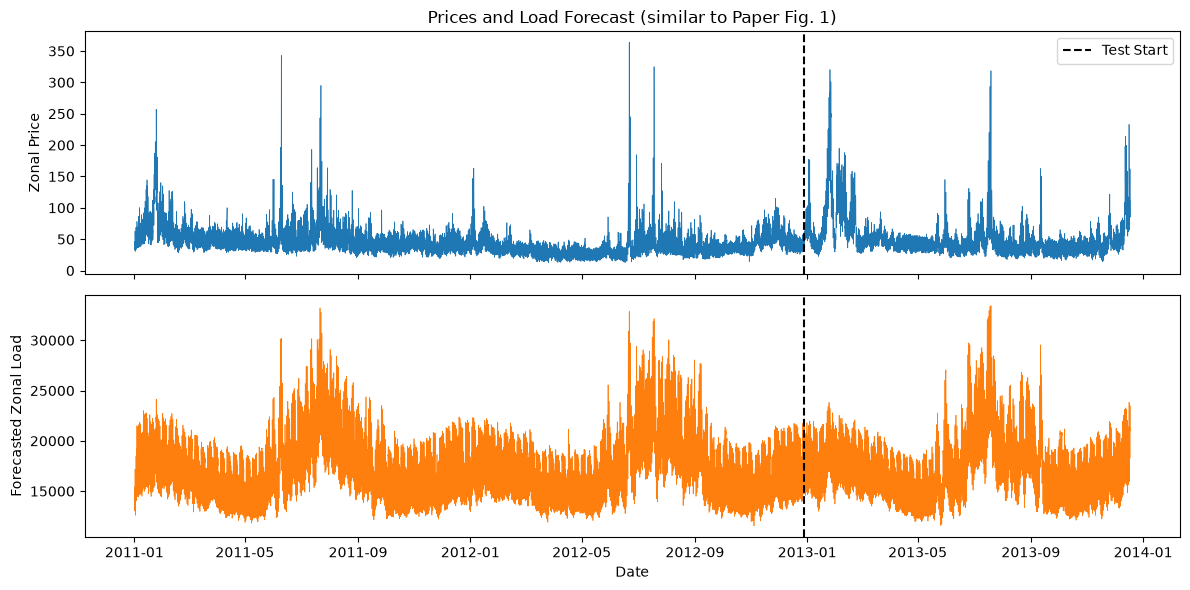

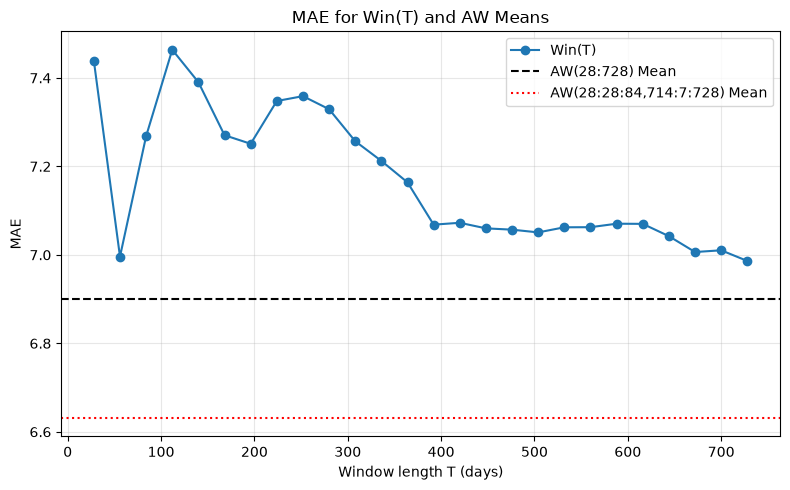

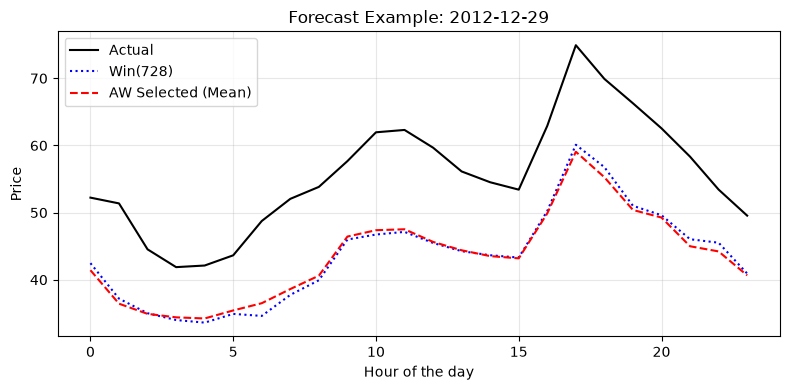


All tasks completed! Files saved in: C:\Users\bertu\OneDrive\Desktop\PA_PROJECT\output_arx_replica


In [7]:


# --- Plot 1: Time Series (Prices and Load) ---
fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
axes[0].plot(df["datetime"], df[PRICE_COL], linewidth=0.5, color='tab:blue')
axes[0].axvline(TEST_START, color="k", linestyle="--", label="Test Start")
axes[0].set_ylabel("Zonal Price")
axes[0].set_title("Prices and Load Forecast (similar to Paper Fig. 1)")
axes[0].legend()

axes[1].plot(df["datetime"], df[LOAD_COL], linewidth=0.5, color='tab:orange')
axes[1].axvline(TEST_START, color="k", linestyle="--")
axes[1].set_ylabel("Forecasted Zonal Load")
axes[1].set_xlabel("Date")
fig.tight_layout()
plt.show()

# --- Plot 2: MAE vs Window Length ---
win_maes = [mae(preds[T], actual) for T in WINDOWS_ALL]
mae_aw_all = mae(np.mean(np.stack([preds[T] for T in WINDOWS_ALL], axis=0), axis=0), actual)
mae_aw_sel = mae(np.mean(np.stack([preds[T] for T in WINDOWS_SEL], axis=0), axis=0), actual)

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(WINDOWS_ALL, win_maes, "o-", label="Win(T)")
ax.axhline(mae_aw_all, color="k", linestyle="--", label="AW(28:728) Mean")
ax.axhline(mae_aw_sel, color="r", linestyle=":", label="AW(28:28:84,714:7:728) Mean")
ax.set_xlabel("Window length T (days)")
ax.set_ylabel("MAE")
ax.set_title("MAE for Win(T) and AW Means")
ax.legend()
ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()

# --- Plot 3: Forecast Example (First Test Day) ---
j0 = 0 
pred_aw_sel_full = np.mean(np.stack([preds[T] for T in WINDOWS_SEL], axis=0), axis=0)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(range(24), actual[j0, :], "k-", label="Actual")
ax.plot(range(24), preds[728][j0, :], "b:", label="Win(728)")
ax.plot(range(24), pred_aw_sel_full[j0, :], "r--", label="AW Selected (Mean)")
ax.set_xlabel("Hour of the day")
ax.set_ylabel("Price")
ax.set_title(f"Forecast Example: {dates[test_idx[j0]].date()}")
ax.legend()
ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()

print(f"\nAll tasks completed! Files saved in: {OUTDIR.resolve()}")